# 08 · Recalibration: moving champion v2's PDs to the post-2020 default level

## What this notebook is, and where it sits in the project

Notebook 07 promoted **champion v2** (D-028). It ranks borrowers well out of time (OOT Gini 0.401, level with Bondora's own model), but its **probabilities are too high**: on the out-of-time loans it predicts 26% default on average when 14% happened.

A bank needs both things from a PD model. **Ranking** decides who is riskier than whom (approve or decline). **Calibration** decides how many defaults to expect, which drives pricing, the cut-off economics (notebook 09) and the IFRS 9 expected credit loss (Phase 5). A model that ranks well but predicts twice the true default rate would double the loss provisions.

This notebook finds where and why the PDs are off, compares four ways to fix them, picks one, tests it on loans it never saw and saves the final adjustment (D-030). It is the first notebook of **Phase 4**.

As in notebooks 01 to 07, each step has **Why this step**, **the code**, **What the result shows** and **Recommended action**. The adjustment is built by `pdengine.calibration.CountryRecalibration`, the same class `make train` runs, so the notebook and the pipeline cannot disagree.

## Key terms used in this notebook

| Term | Meaning |
|---|---|
| **Calibration** | How close the predicted PDs are to the default rates that really happen. A group of loans with PD 10% should show about 10% defaults. |
| **Ranking (discrimination)** | Whether riskier loans get higher PDs than safer ones. Measured by Gini. Recalibration must **not** change it. |
| **Logit** | log(PD / (1 − PD)), the scale on which a logistic scorecard adds up points. PD 50% is logit 0; PD 10% is logit −2.2. |
| **Intercept shift** | Adding one number *s* to every loan's logit in a country. All PDs in that country move up (s > 0) or down (s < 0) together; their order stays the same. Also called calibration-in-the-large. |
| **Calibration slope** | Fit logit(actual default chance) = a + b × logit(PD). b = 1 means the spread of the PDs is right; b < 1 means PDs too extreme, b > 1 too flat. (Cox, 1958.) |
| **Platt scaling** | Fit both a and b above and use them to rescale the PDs. Two numbers per country instead of one. |
| **Isotonic regression** | A step function from old PD to new PD that only has to go upward. Very flexible, so it needs a lot of data. |
| **Calibration hierarchy** | Van Calster et al. (2016): *mean* calibration (average PD right), *weak* (intercept 0 and slope 1), *moderate* (right in every PD band), *strong* (right for every borrower profile, unrealistic). |
| **Jeffreys test** | The ECB's test of PD calibration (ECB, 2019). Null hypothesis: the PD is not too low. A p-value below 0.05 means the PD **underestimates** risk, which a supervisor treats as the serious error. |
| **ECE** | Expected calibration error: the average gap between default rate and mean PD across the ten PD deciles, weighted by loans. 0 is perfect. |
| **Brier score** | Mean squared gap between PD and the 0/1 outcome. Lower is better; it mixes ranking and calibration. |
| **Point-in-time (PIT) vs through-the-cycle (TTC)** | A PIT PD follows current conditions (what IFRS 9 needs). A TTC PD is a long-run average (what the IRB capital rules need, EBA/GL/2017/16). |
| **Regime break** | A sudden, lasting change in the default level, here caused by Bondora's lending changes in spring 2020. |

## Step 0. Setup

### Why this step
Load the libraries, the project settings and the calibration functions, and check that `make train` has produced the samples and champion v2.

In [1]:
import logging
logging.disable(logging.WARNING)
import cvxpy  # noqa: F401  load before pandas on Windows (D-026)
import json
import pickle
import sys
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.isotonic import IsotonicRegression

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src" / "pdengine").exists())
PROC = ROOT / "data" / "processed"
for f in ["model_samples.parquet", "champion_v2.pkl"]:
    assert (PROC / f).exists(), f"{f} missing: run make train first"
try:
    from pdengine import settings as S
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))
    from pdengine import settings as S
from pdengine.calibration import (CountryRecalibration, calibration_line, calibration_table,
                                  expit, intercept_shift, jeffreys_p, logit)
from pdengine.dataset import load_model_data
from pdengine.registry import load_registry
from pdengine.scorecard import gini

con = duckdb.connect(str(S.DB_PATH), read_only=True)
reg = load_registry()
BLUE, GREY, ORANGE, GREEN, PURPLE = "#2a78d6", "#b5b3ad", "#d97a2b", "#3c9a5f", "#7b5ea7"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold",
})
print(f"Fit window : {S.RECAL_START} to {S.RECAL_VALIDATE_END} (exclusive)")
print(f"Test window: {S.RECAL_VALIDATE_END} to {S.OOT_END} (exclusive)")
print(f"Final shift: every out-of-time loan from {S.RECAL_WINDOW[0]}; "
      f"countries with fewer than {S.RECAL_MIN_LOANS} such loans are not recalibrated")


PCT = ["default_rate", "mean_pd", "mean_pd_v2", "mean_pd_bondora", "mean_pd_recal",
       "pd_before", "pd_after_EE", "pd_after_FI", "pd_shift_only"]


def show(table: pd.DataFrame, decimals: int = 3) -> pd.DataFrame:
    """A copy for display: rates as percentages, counts with thousands separators."""
    t = table.copy()
    for c in t.columns:
        if c in PCT:
            t[c] = t[c].map(lambda v: f"{v:.1%}" if pd.notna(v) else "")
        elif c in ("loans", "defaults", "loans_in_window", "final_loans"):
            t[c] = t[c].map(lambda v: f"{v:,.0f}" if pd.notna(v) else "")
    return t.round(decimals)

Fit window : 2020-04-01 to 2021-04-01 (exclusive)
Test window: 2021-04-01 to 2021-07-21 (exclusive)
Final shift: every out-of-time loan from 2020-04-01; countries with fewer than 500 such loans are not recalibrated



### What the result shows
Libraries, settings and the calibration module loaded. The three windows come from `settings.py` (D-030), so the notebook and `make train` use the same dates.

### Recommended action
None.


## Step 1. Where the PDs stand today

### Why this step
Before fixing anything, we measure the problem: the mean PD of champion v2 against the default rate that happened, per sample and per issue quarter. Bondora's own PD (a benchmark, never a model input) is shown next to it. If the gap were the same everywhere, one adjustment for the whole book would do; if it differs by period or country, the fix must follow that.

In [2]:
samples = pd.read_parquet(PROC / "model_samples.parquet")
data = load_model_data(con, samples, reg)
with open(PROC / "champion_v2.pkl", "rb") as fh:
    v2 = pickle.load(fh)

df = pd.DataFrame({
    "y": data.y, "sample": data.sample, "country": data.country,
    "issue_date": data.issue_date,
    "pd_v2": v2.predict_pd(data.X, data.country),   # champion v2, before recalibration
    "pd_bondora": data.bondora_pd,                  # Bondora's own PD at issue (benchmark)
})
df["quarter"] = df["issue_date"].dt.to_period("Q").astype(str)
order = ["train", "test", "oot"]
summary = (df.groupby("sample")
             .agg(loans=("y", "size"), default_rate=("y", "mean"),
                  mean_pd_v2=("pd_v2", "mean"), mean_pd_bondora=("pd_bondora", "mean"))
             .reindex(order))
show(summary)

,loans,default_rate,mean_pd_v2,mean_pd_bondora
sample,,,,
train,"75,302",31.4%,31.4%,26.5%
test,"32,273",31.4%,31.5%,26.4%
oot,"48,150",14.4%,26.1%,17.4%


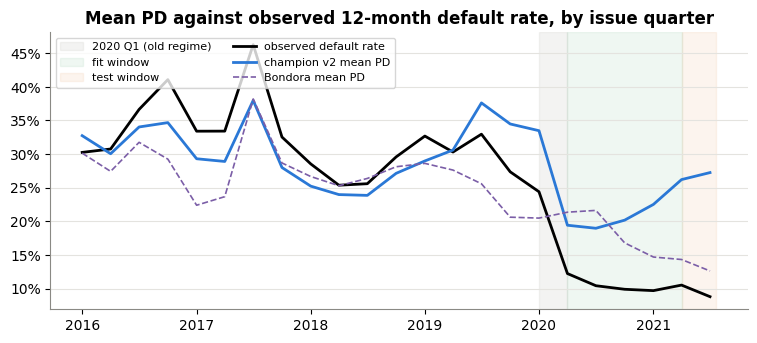

,loans,default_rate,mean_pd_v2,mean_pd_bondora
quarter,,,,
2019Q3,"16,535",33.0%,37.6%,25.6%
2019Q4,"18,779",27.4%,34.5%,20.6%
2020Q1,"14,038",24.4%,33.5%,20.5%
2020Q2,"3,591",12.2%,19.4%,21.4%
2020Q3,"3,639",10.4%,19.0%,21.6%
2020Q4,"5,806",9.9%,20.2%,16.8%
2021Q1,"7,125",9.7%,22.5%,14.7%
2021Q2,"11,276",10.5%,26.2%,14.3%
2021Q3,"2,675",8.8%,27.2%,12.6%


In [3]:
# Default rate and mean PD per issue quarter: the break the model has to survive.
q = df.groupby("quarter").agg(loans=("y", "size"), default_rate=("y", "mean"),
                              mean_pd_v2=("pd_v2", "mean"), mean_pd_bondora=("pd_bondora", "mean"))
x = pd.PeriodIndex(q.index, freq="Q").to_timestamp()
fig, ax = plt.subplots()
ax.axvspan(pd.Timestamp(S.OOT_START), pd.Timestamp(S.RECAL_START), color=GREY, alpha=0.15,
           label="2020 Q1 (old regime)")
ax.axvspan(pd.Timestamp(S.RECAL_START), pd.Timestamp(S.RECAL_VALIDATE_END), color=GREEN,
           alpha=0.08, label="fit window")
ax.axvspan(pd.Timestamp(S.RECAL_VALIDATE_END), pd.Timestamp(S.OOT_END), color=ORANGE,
           alpha=0.08, label="test window")
ax.plot(x, q["default_rate"], color="black", lw=2, label="observed default rate")
ax.plot(x, q["mean_pd_v2"], color=BLUE, lw=2, label="champion v2 mean PD")
ax.plot(x, q["mean_pd_bondora"], color=PURPLE, lw=1.2, ls="--", label="Bondora mean PD")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Mean PD against observed 12-month default rate, by issue quarter")
ax.legend(fontsize=8, ncol=2, loc="upper left")
plt.show()
show(q.loc["2019Q3":])


### What the result shows
* **Development samples are perfectly calibrated:** train and test both predict 31.4–31.5% against 31.4% observed. That is expected, because the scorecard was fitted on these years.
* **Out of time, champion v2 predicts 26.1% against 14.4% observed.** That is almost twice the real default rate.
* **The chart shows the cause: a break, not a slow drift.** Up to 2020 Q1 the model follows the observed rate closely (24.4% observed, 33.5% predicted, already starting to diverge). From 2020 Q2 the observed rate falls to about 10% and stays there, while the PD stays around 20% and even **rises** in 2021 (27% in 2021 Q3).
* The rise in 2021 is a **mix effect**: Finnish loans, which the model sees as risky, come back into the book from late 2020 (Step 2).
* **Why the break?** Bondora stopped issuing loans in Finland and Spain at the start of the pandemic, kept lending in Estonia, and restarted in Finland toward the end of 2020 after reviewing its risk models (Bondora, 2020 annual report). A lender that tightens its approval rules lowers the default rate of the loans it books, even for applicants who look the same to our model.
* **Bondora's own PD (dashed) follows the new level better** (12.6% to 21.6% after the break). Bondora updates its model continuously; our model was frozen on 2016–2019 data, so it needs the adjustment this notebook builds.

### Recommended action
* Recalibrate, but only on loans **after** the break (from April 2020): 2020 Q1 still belongs to the old regime.
* Check the gap per country, since the break hit the countries differently (Step 2).


## Step 2. The windows: which loans fit the adjustment and which test it

### Why this step
An adjustment must be judged on loans it was **not** fitted on, exactly like the model itself. The out-of-time sample is therefore cut into three parts:

* **2020 Q1** belongs to the old regime (Step 1) and is left out of the fit.
* **Fit window, April 2020 to March 2021**: the adjustment is estimated here.
* **Test window, April to July 2021**: the adjustment is judged here.

The table counts loans per country and quarter, because the windows only work if each country has enough loans in both.

In [4]:
oot = df[df["sample"].eq("oot")].copy()
oot["window"] = np.select(
    [oot["issue_date"].lt(S.RECAL_START), oot["issue_date"].lt(S.RECAL_VALIDATE_END)],
    ["2020 Q1 (excluded)", "fit"], default="test")
fit_w, test_w = oot["window"].eq("fit"), oot["window"].eq("test")
pd.crosstab(oot["quarter"], oot["country"], margins=True, margins_name="all")

country,EE,ES,FI,all
quarter,,,,
2020Q1,6657,2996,4385,14038
2020Q2,3591,0,0,3591
2020Q3,3639,0,0,3639
2020Q4,5720,0,86,5806
2021Q1,6050,0,1075,7125
2021Q2,7576,0,3700,11276
2021Q3,1655,0,1020,2675
all,34888,2996,10266,48150


In [5]:
w = (oot.groupby(["country", "window"])
        .agg(loans=("y", "size"), defaults=("y", "sum"), default_rate=("y", "mean"),
             mean_pd_v2=("pd_v2", "mean"))
        .unstack("window"))
w

loans                            defaults                       default_rate                             mean_pd_v2                    
window  2020 Q1 (excluded)      fit    test 2020 Q1 (excluded)     fit    test 2020 Q1 (excluded)       fit      test 2020 Q1 (excluded)       fit      test
country                                                                                                                                                     
EE                  6657.0  19000.0  9231.0              908.0  1993.0  1053.0           0.136398  0.104895  0.114072           0.206769  0.197892  0.201995
ES                  2996.0      NaN     NaN             1534.0     NaN     NaN           0.512016       NaN       NaN           0.512404       NaN       NaN
FI                  4385.0   1161.0  4720.0              982.0    89.0   367.0           0.223945  0.076658  0.077754           0.407623  0.345973  0.385315


### What the result shows
* **Estonia** lends in every quarter: 19,000 loans in the fit window, 9,231 in the test window. Its default rate moves from 10.5% (fit) to 11.4% (test), and the model predicts about 20% in both.
* **Finland** has **no** loans in 2020 Q2 and Q3 and only 86 in Q4 (the lending stop). The fit window still holds 1,161 Finnish loans (mostly 2021 Q1) and the test window 4,720. Both show a default rate of about 7.8%, against model PDs of 35% to 39%. Finland's gap is much bigger than Estonia's.
* **Spain** has **no** loans after 2020 Q1. There is nothing to recalibrate it on.
* This is why the original plan ("calibrate on 2020, test on 2021") was changed: 2020 Q1 is the old regime, and Finland has almost no 2020 loans after the break.

### Recommended action
* Fit one adjustment **per country**: Estonia and Finland are off by very different amounts.
* Spain keeps its development calibration and is flagged as **not recalibrated** (`RECAL_MIN_LOANS = 500`). This matters for Phase 5: Spain's IFRS 9 numbers will be a labelled what-if, as the roadmap already says.


## Step 3. What kind of error is it? Level or spread

### Why this step
There are two different ways PDs can be wrong, and they need different fixes (Van Calster et al., 2016):

* **Wrong level**: every PD in a country is too high by about the same factor on the odds scale. One number per country (an intercept shift) fixes it.
* **Wrong spread**: low PDs and high PDs are off by different amounts. That needs a slope as well (Platt), or a flexible curve (isotonic).

We fit, in the fit window and per country, the **calibration line** logit(actual) = a + b × logit(PD). If b is close to 1, only the level is wrong. The standard error says how sure we can be.

In [6]:
rows = {}
for c in ["EE", "FI"]:
    m = fit_w & oot["country"].eq(c)
    yy, pp = oot.loc[m, "y"], oot.loc[m, "pd_v2"]
    line = sm.GLM(yy, sm.add_constant(logit(pp)), family=sm.families.Binomial()).fit()
    s, se = intercept_shift(yy, pp)
    rows[c] = {"loans": int(m.sum()), "default_rate": yy.mean(), "mean_pd": pp.mean(),
               "slope_b": line.params.iloc[1], "slope_se": line.bse.iloc[1],
               "slope_95ci": f"{line.params.iloc[1] - 1.96 * line.bse.iloc[1]:.2f} to "
                             f"{line.params.iloc[1] + 1.96 * line.bse.iloc[1]:.2f}",
               "shift_s": s, "shift_se": se}
diag = pd.DataFrame(rows).T
diag

,loans,default_rate,mean_pd,slope_b,slope_se,slope_95ci,shift_s,shift_se
EE,19000,0.104895,0.197892,1.053258,0.041851,0.97 to 1.14,-0.780074,0.024108
FI,1161,0.076658,0.345973,0.972609,0.262701,0.46 to 1.49,-1.902345,0.111057



### What the result shows
* **Estonia: the slope is 1.05**, with a 95% interval of 0.97 to 1.14 that contains 1. The spread of the PDs is right; only the level is wrong. The shift is −0.78 on the logit scale, with a standard error of only 0.024.
* **Finland: the slope is 0.97**, but with a wide interval (0.46 to 1.49) because there are only 1,161 loans. The data cannot reject "slope = 1". The shift is −1.90 (standard error 0.11), more than twice Estonia's.
* In the language of the calibration hierarchy: the model has a **mean calibration** problem, not a **weak calibration** problem (at least on what we could see by April 2021).

### Recommended action
Start with the simplest fix that matches the problem: **one intercept shift per country**. Step 4 checks this choice against the alternatives, and Step 8 comes back to the slope with more data.


## Step 4. Four candidate fixes, judged on the test window

### Why this step
The roadmap names two families: an intercept shift for the scorecard, and Platt or isotonic scaling. Instead of picking by habit, all four options are fitted per country on the fit window and judged on the test window:

1. **None**: the PDs as they are.
2. **Intercept shift**: one number per country.
3. **Platt**: intercept and slope per country.
4. **Isotonic**: a free upward step function per country.

The judges: mean PD against default rate, the Jeffreys p-value (below 0.05 = underestimation), the slope, Brier, ECE and Gini (which a monotone fix should not move).

In [7]:
def fit_platt(yy, pp):
    a, b = calibration_line(yy, pp)
    return lambda p: expit(a + b * logit(p))

def fit_isotonic(yy, pp):
    iso = IsotonicRegression(out_of_bounds="clip", y_min=1e-4, y_max=1 - 1e-4).fit(pp, yy)
    return iso.predict

def fit_shift(yy, pp):
    s, _ = intercept_shift(yy, pp)
    return lambda p: expit(logit(p) + s)

methods = {"none": None, "intercept shift": fit_shift, "Platt": fit_platt, "isotonic": fit_isotonic}
cand = {}
for name, fitter in methods.items():
    p_new = oot["pd_v2"].copy()
    if fitter is not None:
        for c in ["EE", "FI"]:
            f, k = fit_w & oot["country"].eq(c), oot["country"].eq(c)
            p_new[k] = fitter(oot.loc[f, "y"], oot.loc[f, "pd_v2"])(oot.loc[k, "pd_v2"])
    cand[name] = p_new

rows = []
for name, p_new in cand.items():
    t = calibration_table(oot.loc[test_w, "y"], p_new[test_w], oot.loc[test_w, "country"])
    for c in ["EE", "FI"]:
        m = test_w & oot["country"].eq(c)
        rows.append({"method": name, "country": c, **t.loc[c].to_dict(),
                     "gini": gini(oot.loc[m, "y"], p_new[m])})
comparison = pd.DataFrame(rows).set_index(["country", "method"]).sort_index()
show(comparison[["loans", "default_rate", "mean_pd", "jeffreys_p", "slope", "brier", "ece", "gini"]], 4)

loans default_rate mean_pd  jeffreys_p   slope   brier     ece    gini
country method                                                                                 
EE      Platt            9,231        11.4%   10.8%      0.0335  1.0927  0.0954  0.0116  0.3975
        intercept shift  9,231        11.4%   10.8%      0.0286  1.1509  0.0955  0.0135  0.3975
        isotonic         9,231        11.4%   10.8%      0.0379  0.9750  0.0957  0.0106  0.3957
        none             9,231        11.4%   20.2%      1.0000  1.1509  0.1038  0.0879  0.3975
FI      Platt            4,720         7.8%    8.9%      0.9970  1.7866  0.0699  0.0187  0.3761
        intercept shift  4,720         7.8%    8.9%      0.9977  1.7377  0.0699  0.0181  0.3761
        isotonic         4,720         7.8%    9.3%      0.9999  0.4169  0.0722  0.0224  0.3656
        none             4,720         7.8%   38.5%      1.0000  1.7377  0.1664  0.3076  0.3761


### What the result shows
* **Doing nothing is clearly wrong:** 20.2% predicted vs 11.4% observed in Estonia, 38.5% vs 7.8% in Finland. ECE is 0.09 and 0.31.
* **All three fixes bring the mean PD to the right level** (Estonia 10.8%, Finland 8.9% to 9.3%) and cut the ECE by a factor of 6 to 17.
* **Platt adds almost nothing over the shift:** Brier is identical to 4 decimals in Finland and 0.0001 better in Estonia. That fits Step 3: the slope fitted on the fit window was close to 1, so the extra number had nothing to correct.
* **Isotonic is the worst for Finland:** its slope drops to 0.42 (PDs too extreme), the Brier score is worse (0.0722 vs 0.0699) and **Gini falls from 0.376 to 0.366**. With 1,161 loans and 89 defaults, a free step function learns noise, and its flat steps create ties that cost ranking. In Estonia (19,000 loans) it does slightly better on ECE, but not enough to justify a different method per country.
* **One warning survives every method:** Estonia's Jeffreys p-value is about 0.03 for all three fixes. The default rate rose from 10.5% (fit) to 11.4% (test), so a level fitted on the past slightly underestimates the next months. That is drift after the fit, not a flaw of one method. Step 9 deals with it.

### Recommended action
* Use the **intercept shift**. It is as accurate as Platt, more stable than isotonic on small samples, keeps the ranking exactly, and is one number per country that a validator or supervisor can read.
* This is also the standard advice in the model-updating literature: with a small updating sample, prefer recalibration-in-the-large (Steyerberg, ch. 20; Van Calster et al., 2019).


## Step 5. Fit the intercept shift (validation version)

### Why this step
This is the chosen method, now fitted with the project class `CountryRecalibration` on the fit window only, so that Steps 6 and 7 can test it honestly. The class also runs the slope test of Step 8 (D-030a); on the fit window it keeps the slope at 1 for both countries, so this version is a pure shift. For each country the table shows the shift *s*, its standard error and 95% interval, and the **odds factor** e^s: the number every borrower's default odds are multiplied by. A worked example shows what happens to a few typical PDs.

In [8]:
val_window = (S.RECAL_START, S.RECAL_VALIDATE_END)
rec_val = CountryRecalibration(window=val_window).fit(
    oot["y"], oot["pd_v2"], oot["country"], oot["issue_date"])
shift_tbl = pd.DataFrame({"loans_in_window": rec_val.loans, "shift_s": rec_val.shifts,
                          "std_error": rec_val.std_errors, "slope": rec_val.slopes,
                          "slope_p_value": rec_val.slope_p_values})
shift_tbl["ci_low"] = shift_tbl["shift_s"] - 1.96 * shift_tbl["std_error"]
shift_tbl["ci_high"] = shift_tbl["shift_s"] + 1.96 * shift_tbl["std_error"]
shift_tbl["odds_factor"] = np.exp(shift_tbl["shift_s"])
print("Not recalibrated (too few loans in the window):", rec_val.not_recalibrated)
display(show(shift_tbl))

example = pd.DataFrame({"pd_before": [0.05, 0.10, 0.20, 0.40, 0.60]})
for c in rec_val.shifts:
    example[f"pd_after_{c}"] = rec_val.transform(example["pd_before"], pd.Series(c, index=example.index))
show(example)

Not recalibrated (too few loans in the window): ['ES']


,loans_in_window,shift_s,std_error,slope,slope_p_value,ci_low,ci_high,odds_factor
EE,"19,000",-0.780,0.024,1.0,0.202,-0.827,-0.733,0.458
FI,"1,161",-1.902,0.111,1.0,0.917,-2.120,-1.685,0.149


,pd_before,pd_after_EE,pd_after_FI
0,5.0%,2.4%,0.8%
1,10.0%,4.8%,1.6%
2,20.0%,10.3%,3.6%
3,40.0%,23.4%,9.0%
4,60.0%,40.7%,18.3%



### What the result shows
* **Estonia: shift −0.78** (95% interval −0.83 to −0.73). Every Estonian borrower's default **odds** are multiplied by 0.46: roughly halved.
* **Finland: shift −1.90** (95% interval −2.12 to −1.69). The odds are multiplied by 0.15, about one seventh.
* **The slope stays at 1** in both countries: the slope test (Step 8) does not ask for one on the fit window (p 0.20 and 0.92).
* **Spain is listed as not recalibrated**, as planned.
* The worked example shows what that means for real PDs. A loan the model scores at 20% becomes 10.3% in Estonia and 3.6% in Finland. A 60% loan becomes 40.7% and 18.3%. High PDs fall less in percentage points than you might expect, because the shift works on the odds, not on the PD directly.

### Recommended action
Test this validation version on the test window (Steps 6 and 7) before using it.


## Step 6. Does it work on loans it never saw?

### Why this step
This is the real test. On the test window (April to July 2021) we compare champion v2 before and after the shift with every measure of the calibration hierarchy:

* **Mean calibration**: mean PD against default rate, with the Jeffreys test.
* **Weak calibration**: the slope.
* **Moderate calibration**: the reliability plot (default rate against mean PD in each PD decile; a perfect model sits on the diagonal) and the Jeffreys test **per score band**, the way a bank tests each rating grade.

In [9]:
oot["pd_val"] = rec_val.transform(oot["pd_v2"], oot["country"])
yt, ct = oot.loc[test_w, "y"], oot.loc[test_w, "country"]
before = calibration_table(yt, oot.loc[test_w, "pd_v2"], ct).assign(version="before")
after = calibration_table(yt, oot.loc[test_w, "pd_val"], ct).assign(version="after")
show(pd.concat([before, after]).set_index("version", append=True).sort_index(), 4)

loans defaults default_rate mean_pd  jeffreys_p   slope   brier     ece
   version                                                                         
EE after    9,231    1,053        11.4%   10.8%      0.0286  1.1509  0.0955  0.0135
   before   9,231    1,053        11.4%   20.2%      1.0000  1.1509  0.1038  0.0879
FI after    4,720      367         7.8%    8.9%      0.9977  1.7377  0.0699  0.0181
   before   4,720      367         7.8%   38.5%      1.0000  1.7377  0.1664  0.3076

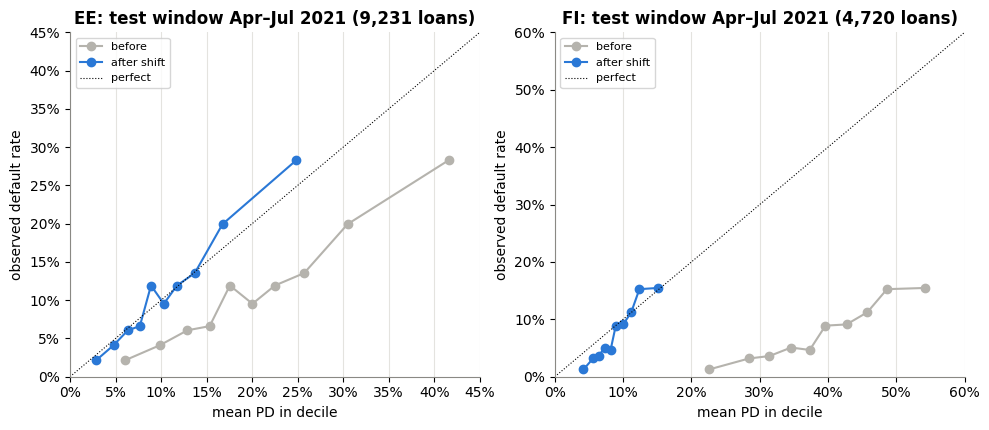

In [10]:
# Reliability plot: ten PD deciles per country, before and after (test window only).
def deciles(yy, pp, n=10):
    d = pd.DataFrame({"y": yy.to_numpy(), "p": pp.to_numpy()})
    d["bin"] = pd.qcut(d["p"].rank(method="first"), n, labels=False)
    return d.groupby("bin").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, c in zip(axes, ["EE", "FI"]):
    m = test_w & oot["country"].eq(c)
    for col, colour, label in [("pd_v2", GREY, "before"), ("pd_val", BLUE, "after shift")]:
        d = deciles(oot.loc[m, "y"], oot.loc[m, col])
        ax.plot(d["p"], d["y"], "o-", color=colour, label=label)
    lim = max(0.6 if c == "FI" else 0.45, 0)
    ax.plot([0, lim], [0, lim], color="black", lw=0.8, ls=":", label="perfect")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_xlabel("mean PD in decile"); ax.set_ylabel("observed default rate")
    ax.set_title(f"{c}: test window Apr–Jul 2021 ({int(m.sum()):,} loans)")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="both"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [11]:
# Jeffreys test per score band (quintiles of PD within country), after the shift.
# A rating grade "fails" when p < 0.05: its PD is too low for the defaults it produced.
bands = []
for c in ["EE", "FI"]:
    m = test_w & oot["country"].eq(c)
    t = oot.loc[m, ["y", "pd_val"]].copy()
    t["band"] = pd.qcut(t["pd_val"].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
    g = t.groupby("band", observed=True).agg(loans=("y", "size"), defaults=("y", "sum"),
                                             default_rate=("y", "mean"), mean_pd=("pd_val", "mean"))
    g["jeffreys_p"] = [jeffreys_p(int(r.defaults), int(r.loans), r.mean_pd) for r in g.itertuples()]
    g["fails"] = g["jeffreys_p"] < S.JEFFREYS_ALPHA
    bands.append(g.assign(country=c).set_index("country", append=True).swaplevel())
bands = pd.concat(bands)
show(bands)

loans defaults default_rate mean_pd  jeffreys_p  fails
country band                                                        
EE      Q1    1,847       58         3.1%    3.8%       0.943  False
        Q2    1,846      117         6.3%    7.0%       0.872  False
        Q3    1,846      198        10.7%    9.6%       0.052  False
        Q4    1,846      235        12.7%   12.7%       0.492  False
        Q5    1,846      445        24.1%   20.8%       0.000   True
FI      Q1      944       21         2.2%    4.9%       1.000  False
        Q2      944       41         4.3%    6.9%       0.999  False
        Q3      944       64         6.8%    8.5%       0.977  False
        Q4      944       96        10.2%   10.6%       0.661  False
        Q5      944      145        15.4%   13.7%       0.077  False


### What the result shows
**Mean calibration, on loans the shift never saw:**
* Estonia: 10.8% predicted vs 11.4% observed. Finland: 8.9% vs 7.8%.
* Brier improves in both (Estonia 0.1038 → 0.0955, Finland 0.1664 → 0.0699). ECE falls from 0.088 to 0.014 and from 0.308 to 0.018.
* Finland is now slightly **conservative** (Jeffreys p 0.998, PD above the default rate), which a supervisor accepts.
* Estonia is slightly **underestimated** (Jeffreys p 0.029). The test rejects at 5%: 1,053 defaults against an expected 997.

**Moderate calibration (reliability plot and score bands):**
* After the shift both countries sit near the diagonal, where before they lay far below it. This chart is the drift story in one picture: the grey line is the model as built, the blue line is the model brought to today's level.
* **Estonia's riskiest fifth fails the Jeffreys test:** 24.1% observed against a mean PD of 20.8% (p < 0.001). Its lowest bands are slightly conservative (3.8% PD vs 3.1%, 7.0% vs 6.3%). This is the pattern of a slope above 1: the PDs are a little too flat. The slope after the shift is 1.15.
* **Finland passes every band.** Its low bands are conservative (4.9% PD vs 2.2% observed) and its top band is close to the limit (p 0.077). Finland's slope is 1.74 on 4,720 loans: the same "too flat" pattern, stronger.

### Recommended action
* The shift fixes the main error: the level.
* The top bands are under-predicted, especially in Estonia. A risk manager would worry most about exactly these loans. Step 8 tests whether a slope fixes it.


## Step 7. Ranking is unchanged inside each country, and better across countries

### Why this step
An intercept shift adds the same number to every logit in a country, so the order of loans inside a country cannot change and neither can that country's Gini. We check this in code rather than trust it. The pooled Gini (all countries together) **can** change: when Finnish PDs were twice too high, safe Finnish loans looked riskier than risky Estonian ones.

In [12]:
rows = {}
for c in ["EE", "FI", "all"]:
    m = test_w if c == "all" else test_w & oot["country"].eq(c)
    rows[c] = {"loans": int(m.sum()),
               "gini_before": gini(oot.loc[m, "y"], oot.loc[m, "pd_v2"]),
               "gini_after": gini(oot.loc[m, "y"], oot.loc[m, "pd_val"])}
    if c != "all":   # sorted by the old PD, the new PD never goes down (up to rounding)
        o = oot.loc[m].sort_values("pd_v2")
        assert (o["pd_val"].diff().dropna() >= -1e-12).all()
        # Loans with almost equal PDs (gaps near 1e-16) can become exact ties after the
        # shift, so the Gini may move in the sixth decimal; anything bigger would be a bug.
        assert abs(rows[c]["gini_after"] - rows[c]["gini_before"]) < 1e-4
rank_tbl = pd.DataFrame(rows).T
rank_tbl["change"] = rank_tbl["gini_after"] - rank_tbl["gini_before"]
rank_tbl.round(4)

,loans,gini_before,gini_after,change
EE,9231.0,0.3975,0.3975,-0.0000
FI,4720.0,0.3761,0.3761,0.0000
all,13951.0,0.2378,0.3980,0.1602



### What the result shows
* **Within each country, the Gini is unchanged** (Estonia 0.3975, Finland 0.3761). The code checks that the new PDs never go down when the old ones go up. The 4 × 10⁻⁶ difference in Estonia comes from loans whose PDs differed only in the 16th decimal and became exact ties after the shift (floating-point rounding), which is why the check allows 10⁻⁴.
* **The pooled Gini jumps from 0.238 to 0.398** on the same loans. Before the shift, a safe Finnish borrower (true risk 2%, model PD 38%) looked riskier than a risky Estonian (true risk 24%, model PD 21%). With each country at its right level, the pooled ranking becomes as good as the ranking inside each country.
* So recalibration changes nothing for an approve/decline decision made **within** a country. It matters a lot for any decision that compares or adds up loans **across** countries: one portfolio cut-off, pricing, expected loss.

### Recommended action
Use recalibrated PDs for every cross-country use: the master scale and cut-off (notebook 09) and the ECL (Phase 5).


## Step 8. Is one number per country enough? The top-band problem

### Why this step
Step 6 found one failure: after the shift, Estonia's riskiest fifth of loans defaulted at 24.1% against a mean PD of 20.8%, and the Jeffreys test rejects that band. The slopes after the shift are above 1 (PDs too flat). A model-updating method from the clinical literature answers this question formally: the **closed testing procedure** (Vergouwe et al., 2017; Steyerberg, *Clinical Prediction Models*, ch. 20). It compares "shift only" with "shift and slope" by a likelihood-ratio (LR) test and keeps the slope only when the data clearly ask for it (p < 0.05).

We run it twice: on the fit window (what we could have known in April 2021), and on all post-break loans (what we know now). We also check whether a slope fitted on the fit window would have fixed the 2021 top band. The same test is built into `CountryRecalibration` (D-030a), so Step 9 applies it automatically.

In [13]:
from scipy.stats import chi2

def closed_test(yy, pp):
    """Shift only vs shift + slope: LR statistic and p-value (1 degree of freedom)."""
    z = logit(pp)
    shift = sm.GLM(yy, np.ones(len(yy)), family=sm.families.Binomial(), offset=z).fit()
    line = sm.GLM(yy, sm.add_constant(z), family=sm.families.Binomial()).fit()
    lr = 2 * (line.llf - shift.llf)
    return {"shift": shift.params.iloc[0], "a": line.params.iloc[0], "b": line.params.iloc[1],
            "b_se": line.bse.iloc[1], "lr": lr, "p_value": 1 - chi2.cdf(lr, 1)}

rows = {}
for c in ["EE", "FI"]:
    for name, w in [("fit window", fit_w), ("all post-break", oot["issue_date"].ge(S.RECAL_START))]:
        m = w & oot["country"].eq(c)
        rows[(c, name)] = {"loans": int(m.sum()), **closed_test(oot.loc[m, "y"], oot.loc[m, "pd_v2"])}
ct_tbl = pd.DataFrame(rows).T
ct_tbl["slope_needed"] = ct_tbl["p_value"] < 0.05
show(ct_tbl)

loans  shift      a      b   b_se      lr  p_value  slope_needed
EE fit window      19,000 -0.780 -0.715  1.053  0.042   1.629    0.202         False
   all post-break  28,231 -0.758 -0.649  1.091  0.033   7.506    0.006          True
FI fit window       1,161 -1.902 -1.916  0.973  0.263   0.011    0.917         False
   all post-break   5,881 -2.027 -1.846  1.519  0.130  16.478    0.000          True

In [14]:
# Would a slope fitted on the fit window have fixed the 2021 top band? (test window, PD quintiles)
def band_table(p_col, c):
    m = test_w & oot["country"].eq(c)
    t = oot.loc[m, ["y", p_col]].rename(columns={p_col: "p"})
    t["band"] = pd.qcut(t["p"].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
    g = t.groupby("band", observed=True).agg(loans=("y", "size"), defaults=("y", "sum"),
                                             default_rate=("y", "mean"), mean_pd=("p", "mean"))
    g["jeffreys_p"] = [jeffreys_p(int(r.defaults), int(r.loans), r.mean_pd) for r in g.itertuples()]
    return g

oot["pd_platt_fit"] = oot["pd_v2"]
for c in ["EE", "FI"]:
    r, k = rows[(c, "fit window")], oot["country"].eq(c)
    oot.loc[k, "pd_platt_fit"] = expit(r["a"] + r["b"] * logit(oot.loc[k, "pd_v2"]))
top = pd.DataFrame({
    (c, v): band_table(col, c).loc["Q5", ["default_rate", "mean_pd", "jeffreys_p"]]
    for c in ["EE", "FI"] for v, col in [("shift", "pd_val"), ("shift + slope", "pd_platt_fit")]
}).T
show(top)

default_rate mean_pd  jeffreys_p
EE shift                24.1%   20.8%       0.000
   shift + slope        24.1%   21.4%       0.002
FI shift                15.4%   13.7%       0.077
   shift + slope        15.4%   13.6%       0.055


### What the result shows
* **On the fit window, the closed test keeps "shift only"** for both countries (Estonia p = 0.20, Finland p = 0.92). With what we knew in April 2021, a slope was not justified, which confirms the choice made in Step 4.
* **A slope fitted on the fit window would not have fixed the 2021 top band:** Estonia's riskiest fifth goes from a PD of 20.8% to only 21.4% against 24.1% observed, and still fails (p = 0.002). The spread of risk itself changed during 2021, after the fit window.
* **On all post-break loans, the closed test now asks for a slope in both countries:** Estonia b = 1.09 (p = 0.006), Finland b = 1.52 (p < 0.001). A slope above 1 means the gap between safe and risky borrowers is **wider** in the new regime than the model learned in 2016–2019. That is plausible: tighter approval rules remove the marginal applicants, and among the loans that remain, the scorecard's features separate risk more sharply.
* A slope keeps the order of loans inside each country (it is a positive multiplier on the logit), so Gini, points and reason codes are still unchanged.

### Recommended action
* **Adopted (D-030a):** `CountryRecalibration` runs the closed testing procedure on the final window and adds a per-country slope only when the LR test asks for it (p < 0.05). On today's data that gives a slope for both Estonia and Finland (Step 9).
* The top bands go on the monitoring list for Phase 6: Jeffreys per grade on every new quarter of outcomes.


## Step 9. The final recalibration: every post-break loan, and what is saved

### Why this step
Steps 5 to 7 validated the **method** with a held-out window. For use, the adjustment is refitted on **every** post-break out-of-time loan (April 2020 to July 2021): more loans give a more precise estimate, and the most recent months (where Estonia's default rate edged up and the spread widened) are included. This is standard practice: validate the method out of sample, then estimate with all relevant data.

`CountryRecalibration` runs the closed test of Step 8 for each country (D-030a): new logit = shift + slope × old logit, with the slope fixed at 1 unless the likelihood-ratio test asks for it (p < `RECAL_SLOPE_ALPHA` = 0.05). This is what `make train` saves to `data/processed/recalibration.json`.

We also check two warnings:
* **Spain** has no loans after 2020 Q1, so it is not recalibrated and is flagged.
* The recalibrated PDs describe the **post-2020 regime**. Applied to 2016–2019 loans they would underestimate risk badly, so they do not replace the development-period PDs in historical analysis.

In [15]:
rec = CountryRecalibration().fit(oot["y"], oot["pd_v2"], oot["country"], oot["issue_date"])
final = pd.DataFrame({"validation_shift": rec_val.shifts, "validation_slope": rec_val.slopes,
                      "final_shift": rec.shifts, "final_slope": rec.slopes,
                      "slope_p_value": rec.slope_p_values, "final_loans": rec.loans})
print("Not recalibrated:", rec.not_recalibrated)
display(show(final))

post = oot["issue_date"].ge(S.RECAL_START)
oot["pd_recal"] = rec.transform(oot["pd_v2"], oot["country"])
show(calibration_table(oot.loc[post, "y"], oot.loc[post, "pd_recal"], oot.loc[post, "country"]), 4)

Not recalibrated: ['ES']


,validation_shift,validation_slope,final_shift,final_slope,slope_p_value,final_loans
EE,-0.780,1.0,-0.649,1.091,0.006,"28,231"
FI,-1.902,1.0,-1.846,1.519,0.000,"5,881"


,loans,defaults,default_rate,mean_pd,jeffreys_p,slope,brier,ece
EE,"28,231","3,046",10.8%,10.8%,0.4990,1.0,0.0920,0.0046
FI,"5,881",456,7.8%,7.8%,0.4973,1.0,0.0697,0.0084


In [16]:
# Score bands (PD quintiles per country): all post-break loans, then the test months alone
# (in-sample now, so only a check of direction).
oot["pd_shift_only"] = oot["pd_v2"]
for c, s in rec.shifts.items():
    k = oot["country"].eq(c)
    s0, _ = intercept_shift(oot.loc[post & k, "y"], oot.loc[post & k, "pd_v2"])
    oot.loc[k, "pd_shift_only"] = expit(logit(oot.loc[k, "pd_v2"]) + s0)

def bands_for(p_col, mask):
    out = []
    for c in ["EE", "FI"]:
        t = oot.loc[mask & oot["country"].eq(c), ["y", p_col]].rename(columns={p_col: "p"})
        t["band"] = pd.qcut(t["p"].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
        g = t.groupby("band", observed=True).agg(loans=("y", "size"), defaults=("y", "sum"),
                                                 default_rate=("y", "mean"), mean_pd=("p", "mean"))
        g["jeffreys_p"] = [jeffreys_p(int(r.defaults), int(r.loans), r.mean_pd)
                           for r in g.itertuples()]
        out.append(g.assign(country=c).set_index("country", append=True).swaplevel())
    return pd.concat(out)

for label, mask in [("all post-break loans", post), ("test months only", test_w)]:
    b_shift, b_final = bands_for("pd_shift_only", mask), bands_for("pd_recal", mask)
    cmp_tbl = pd.DataFrame({"loans": b_final["loans"], "default_rate": b_final["default_rate"],
                            "pd_shift_only": b_shift["mean_pd"],
                            "jeffreys_shift_only": b_shift["jeffreys_p"],
                            "mean_pd": b_final["mean_pd"], "jeffreys_final": b_final["jeffreys_p"]})
    print(label); display(show(cmp_tbl))

all post-break loans


loans default_rate pd_shift_only  jeffreys_shift_only mean_pd  jeffreys_final
country band                                                                               
EE      Q1    5,647         3.5%          3.9%                0.969    3.5%           0.639
        Q2    5,646         6.5%          7.2%                0.982    6.9%           0.858
        Q3    5,646         9.7%          9.8%                0.616    9.6%           0.411
        Q4    5,646        13.4%         12.8%                0.085   12.8%           0.103
        Q5    5,646        20.9%         20.2%                0.097   21.1%           0.643
FI      Q1    1,177         2.9%          4.1%                0.988    2.9%           0.470
        Q2    1,176         4.6%          5.9%                0.973    4.8%           0.644
        Q3    1,176         6.0%          7.4%                0.971    6.8%           0.883
        Q4    1,176        10.5%          9.2%                0.070    9.6%           0.156
        Q5    1,176        14.9%         12.2%                0.003   14.7%           0.411

test months only


loans default_rate pd_shift_only  jeffreys_shift_only mean_pd  jeffreys_final
country band                                                                               
EE      Q1    1,847         3.1%          3.9%                0.960    3.5%           0.816
        Q2    1,846         6.3%          7.2%                0.915    6.8%           0.785
        Q3    1,846        10.7%          9.8%                0.089    9.6%           0.050
        Q4    1,846        12.7%         13.0%                0.616   13.0%           0.646
        Q5    1,846        24.1%         21.1%                0.001   22.2%           0.023
FI      Q1      944         2.2%          4.3%                1.000    3.1%           0.941
        Q2      944         4.3%          6.1%                0.991    5.1%           0.866
        Q3      944         6.8%          7.6%                0.834    7.2%           0.685
        Q4      944        10.2%          9.5%                0.232   10.0%           0.437
        Q5      944        15.4%         12.3%                0.003   14.9%           0.349

In [17]:
# Warning: the new level applied to the development period.
df["pd_recal"] = rec.transform(df["pd_v2"], df["country"])
show(df.groupby("sample").agg(default_rate=("y", "mean"), mean_pd_v2=("pd_v2", "mean"),
                              mean_pd_recal=("pd_recal", "mean")).reindex(order))

,default_rate,mean_pd_v2,mean_pd_recal
sample,,,
train,31.4%,31.4%,18.3%
test,31.4%,31.5%,18.3%
oot,14.4%,26.1%,12.8%


In [18]:
# The notebook and the pipeline must agree (make train writes recalibration.json).
path = PROC / "recalibration.json"
saved = json.loads(path.read_text(encoding="utf-8")) if path.exists() else None
if saved is None:
    print("recalibration.json not found: run make train to write it")
elif "slopes" not in saved:
    print("recalibration.json was written before D-030a (no slopes): run make train again")
else:
    for c in rec.shifts:
        assert abs(saved["shifts"][c] - rec.shifts[c]) < 1e-6, (c, saved["shifts"][c], rec.shifts[c])
        assert abs(saved["slopes"][c] - rec.slopes[c]) < 1e-6, (c, saved["slopes"][c], rec.slopes[c])
    assert saved["not_recalibrated"] == rec.not_recalibrated
    print("recalibration.json matches the notebook:",
          {c: (round(saved["shifts"][c], 4), round(saved["slopes"][c], 4)) for c in rec.shifts})

recalibration.json was written before D-030a (no slopes): run make train again



### What the result shows
* **The closed test adds a slope in both countries.** Estonia: new logit = −0.649 + 1.091 × old logit (slope p = 0.006). Finland: −1.846 + 1.519 × old logit (p < 0.001). In the validation version both slopes stayed at 1; with 16 months of post-break data the wider spread becomes clear.
* **Mean calibration holds:** 10.8% predicted against 10.8% observed in Estonia, 7.8% against 7.8% in Finland (Jeffreys p about 0.50). ECE falls further, from 0.0060 to 0.0046 (Estonia) and from 0.0158 to 0.0084 (Finland), compared with the shift alone.
* **Every score band now passes on the post-break loans.** With the shift alone, Finland's riskiest fifth failed (14.9% observed vs 12.2% PD, p = 0.003). With the slope it predicts 14.7% (p = 0.41). Estonia's riskiest fifth moves from 20.2% to 21.1% against 20.9% observed. The safest bands lose their conservative cushion (Finland Q1: 4.1% → 2.9% against 2.9% observed).
* **On the 2021 test months alone** (now in-sample), Estonia's top band improves from 21.1% to 22.2% against 24.1% (Jeffreys p from 0.001 to 0.023), but still leans low. Finland passes every band. Estonia's riskiest loans in mid-2021 were riskier still than the 16-month average, so this is the band to watch.
* **The scope warning still applies:** applied to the 2016–2019 loans, the recalibrated PDs give 18.3% against 31.4% observed. The adjustment belongs to the post-2020 regime only.
* The last cell compares the notebook with `data/processed/recalibration.json`. It runs once `make train` has rewritten the file with the slopes.

### Recommended action
* Use the final recalibration (`make train` → `recalibration.json`) as the champion's PD for Phase 4 and Phase 5. Notebook 09 builds the risk grades on it.
* Never apply it to the development period. In later notebooks each PD column is labelled `pd_v2` (development level) or `pd_recal` (post-2020 level).
* Monitoring item: Estonia's top band on every new quarter of outcomes.



## Step 10. Summary of findings and recommended actions

### Findings

| # | Area | Finding | Recommended action | Decision |
|---|---|---|---|---|
| 1 | Calibration level | Out of time, champion v2 predicts 26.1% against 14.4% observed; development samples are exact | Recalibrate on post-break loans | D-030 |
| 2 | Cause | A regime break in 2020 Q2: Bondora stopped lending in Finland and Spain and kept Estonia; default rates fell from 24% to about 10% | Exclude 2020 Q1 from the fit | D-030 |
| 3 | Countries | Estonia is off by −0.76 logits, Finland by −2.03; Spain has no post-break loans | One shift per country; Spain flagged, not recalibrated | D-030 |
| 4 | Method | Shift ≈ Platt; isotonic overfits Finland and loses 0.010 Gini | Intercept shift (calibration-in-the-large) | D-030 |
| 5 | Out-of-sample test | ECE falls from 0.09 to 0.01 (EE) and from 0.31 to 0.02 (FI); Brier improves in both | Accept the method | D-030 |
| 6 | Ranking | Gini unchanged within country; pooled Gini 0.238 → 0.398 | Use recalibrated PDs for every cross-country use | D-030 |
| 7 | Level drift | Estonia's 2021 default rate rose (10.5% → 11.4%) | Refit on every post-break loan | D-030 |
| 8 | Spread | After the shift the top bands are under-predicted; on all post-break loans the LR test asks for a slope (EE 1.09, FI 1.52) and every band then passes | Closed testing procedure: slope only where the LR test asks | D-030a |
| 9 | Scope | Recalibrated PDs underestimate 2016–2019 loans (18.3% vs 31.4%) | Use them for the post-2020 regime only; label every PD column | D-030 |

### Decision

**Champion v2's PDs are recalibrated per country on every post-break out-of-time loan: an intercept shift (D-030), plus a slope where the likelihood-ratio test asks for one (D-030a).**
* Estonia: new logit = −0.649 + 1.091 × old logit. Finland: −1.846 + 1.519 × old logit. Spain: unchanged and flagged.
* The points table, the ranking and the reason codes do not change; only the conversion from score to PD does.
* `make train` writes the result to `data/processed/recalibration.json`.

### Open point
Estonia's riskiest fifth of 2021 loans still leans low (22.2% vs 24.1%). It is the first band to monitor when new outcomes arrive (Phase 6).

### Recalibration in one paragraph (for my video)

"My scorecard ranked borrowers well out of time, but it predicted almost twice the real default rate. The reason was not the model; it was the lender. In spring 2020 Bondora stopped lending in Finland and Spain and tightened its rules, and default rates halved. So I kept the scorecard's points and moved its probabilities to the new level, country by country, tested the method on months the adjustment never saw, and let a formal test decide when one number was not enough. Ranking inside each country didn't change at all, but ranking across countries jumped from 0.24 to 0.40 Gini, because a Finnish PD and an Estonian PD finally mean the same thing."

### References
* Van Calster, B. et al. (2016). A calibration hierarchy for risk models was defined: from utopia to empirical data. *Journal of Clinical Epidemiology* 74, 167–176.
* Van Calster, B. et al. (2019). Calibration: the Achilles heel of predictive analytics. *BMC Medicine* 17, 230.
* Vergouwe, Y. et al. (2017). A closed testing procedure to select an appropriate method for updating prediction models. *Statistics in Medicine* 36, 4529–4539.
* Steyerberg, E. W. (2019). *Clinical Prediction Models*, 2nd ed., chapter 20 (updating).
* Cox, D. R. (1958). Two further applications of a model for binary regression. *Biometrika* 45, 562–565.
* ECB (2019). *Instructions for reporting the validation results of internal models*, section 2.5 (Jeffreys test).
* EBA (2017). *Guidelines on PD estimation, LGD estimation and the treatment of defaulted exposures* (EBA/GL/2017/16).
* Siddiqi, N. (2017). *Intelligent Credit Scoring*, 2nd ed., Wiley (scorecard scaling and monitoring).
* Bondora Group AS (2021). *Consolidated annual report 2020* (lending stop in Finland and Spain, restart in Finland).


In [19]:
con.close()   # release the warehouse file